# Solar capacity: a slow input that arrives late

How much solar is installed in the TEPCO area, quarter by quarter, and **when each figure became known**. The source is METI's FIT/FIP disclosure. This notebook probes it end to end (what it publishes, its history, its layout) and designs its capture, ODS tables, `known_at` rule and DWS estimate.

**Why it gets a notebook of its own.** No other input is used in as many places:

| Where | What it does | If it's wrong |
| --- | --- | --- |
| Headline metric (PRD) | MAE is normalised by capacity | Every reported score shifts |
| Weather inputs (PRD) | Weather points are averaged by solar capacity per prefecture | The weather features lean toward the wrong prefectures |
| Model input | Capacity estimate | A wrong value becomes a bias |
| F5 range check | Output must stay under capacity | Too low blocks good days; too high hides a unit bug |
| Output check at prediction time | "Under capacity" | As F5 |
| F8 drift scenario | "Normalise by capacity" is the fix | The fix itself is off |

**The figure is 4.0 to 8.6 months old on the day it is used** (median 6.4 months, over the training window). Each quarter's figures come out about four to five and a half months after the quarter ends, and then age for three more months until the next release. Tomorrow's forecast (2026-11-17) uses the figure for the end of March 2026: 231 days old. No other input comes anywhere near this; the others are known within hours of the time they describe. That gap has three consequences, each measured below:

1. **A leak that looks right.** Joining capacity on the date it describes ("the end of March") uses a number nobody had until August. The fix is `known_at`, and even that is subtle here: the publisher later **revised its own publication dates**, mostly backwards (section 2)
2. **A bias.** The fleet grows about 1% a quarter while the figure ages, so carrying the newest figure runs about 2% low. A straight-line trend through the newest four releases cuts the error to under 0.5% (section 7)
3. **A jump.** When a new release lands, the estimate, and every forecast scaled by it, moves by up to about 2% overnight with no change in the weather (section 7)

| Question | Where |
| --- | --- |
| What does the source publish, and on what terms? | Section 1 |
| When did each release become known? | Section 2 |
| How old is the figure when it is used? | Section 3 |
| Is the layout stable, and what shape should ODS take? | Section 4 |
| What is the TEPCO area's capacity, with Shizuoka cut at the Fuji River? | Section 5 |
| Does it agree with what the grid saw? | Section 6 |
| Carry the stale figure, or extrapolate? | Section 7 |
| How should the nine weather points be weighted? | Section 8 |

Claims are labelled as in the earlier notebooks: **Observed** (a cell shows it) or **Source** (quoted from the publisher, with a link; Japanese quotes are translated). [What this exploration made known](#What-this-exploration-made-known) sums it up, with what is still open, and [Where the sources and the data disagree](#Where-the-sources-and-the-data-disagree) collects the mismatches.

## 0. Setup

**Step.** Every download is cached under `data/probe/capacity/` (gitignored), with its response headers next to it, as in notebooks 00 and 01: re-running a cell never hits the publisher again, and headers such as `Last-Modified` are kept as evidence. Release files are cached once (their content is fixed); the page itself once per day, since its notices change. Requests are spaced two seconds apart (three for the Wayback Machine).

In [1]:
import gzip
import io
import json
import os
import re
import time
import unicodedata
from datetime import UTC, datetime
from email.utils import parsedate_to_datetime
from html import unescape
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
from google.cloud import bigquery

from jtf.ingest.fetch import USER_AGENT
from jtf.ingest.sources import JST, WEATHER_POINTS

PAGE = "https://www.fit-portal.go.jp/PublicInfoSummary"
FILE_URL = "https://www.fit-portal.go.jp/servlet/servlet.FileDownload?file={}"
CACHE = Path("../data/probe/capacity")
NOW = datetime.now(JST)
TODAY = NOW.date()
client = httpx.Client(timeout=120, follow_redirects=True, headers={"User-Agent": USER_AGENT})
pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)


def fetch(url: str, path: Path, pause: float = 2.0) -> tuple[bytes, dict]:
    """Download once and keep the headers next to the body; later calls read the cache."""
    head_path = path.with_name(path.name + ".headers.json")
    if not (path.exists() and head_path.exists()):
        time.sleep(pause)
        r = client.get(url)
        r.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(r.content)
        head = {k.lower(): v for k, v in r.headers.items() if k.lower() != "set-cookie"}
        head["x-fetched-at"] = datetime.now(UTC).isoformat()
        head_path.write_text(json.dumps(head))
    return path.read_bytes(), json.loads(head_path.read_text())


def text_lines(html: bytes) -> list[str]:
    """The visible text of a page, one line per element, full-width characters folded (NFKC)."""
    if html[:2] == b"\x1f\x8b":
        html = gzip.decompress(html)
    s = re.sub(r"<(script|style)[^>]*>.*?</\1>", "", html.decode("utf-8", "replace"), flags=re.S)
    lines = unescape(re.sub(r"<[^>]+>", "\n", s)).splitlines()
    return [unicodedata.normalize("NFKC", line).strip() for line in lines if line.strip()]


def month_end(year, month) -> pd.Timestamp:
    return pd.Timestamp(int(year), int(month), 1) + pd.offsets.MonthEnd()


print(f"probing at {NOW:%Y-%m-%d %H:%M} JST")

probing at 2026-11-16 09:06 JST


## 1. The source

**Step: read the page before any file.** METI's Agency for Natural Resources and Energy runs the [FIT/FIP disclosure site](https://www.fit-portal.go.jp/PublicInfoSummary) (再生可能エネルギー電気の利用の促進に関する特別措置法 情報公表用ウェブサイト, "disclosure site for the renewable electricity act"). Its summary page has a notices list, national totals, the definitions, and one download link per table and quarter. Print the notices and the two definitions that decide what the numbers mean.

In [2]:
page, page_headers = fetch(PAGE, CACHE / "page" / f"{TODAY}.html")
lines = text_lines(page)
start = lines.index("■お知らせ")
print("\n".join(lines[start : start + 9]))
print()
for prefix in ("当表で「導入」", "※4", "※5"):
    print(next(line for line in lines if line.startswith(prefix)))

■お知らせ
2026.8.18
>2026年3月末時点の導入状況等を公表しました。
2026.6.4
>2025年12月末時点の導入状況等を公表しました。
2026.3.19
>2025年9月末時点の導入状況等を公表しました。
2025.12.09
>2025年6月末時点の導入状況等を公表しました。

当表で「導入」と表現するのは、再生可能エネルギー電気の利用の促進に関する特別措置法の下で買取が開始された状態をいいます。
※4 一部のデータについては確認中であるため、僅かな誤差を含みます。
※5 B表(市町村別認定・導入量)において、市区町村に統廃合があった場合は、旧市区町村の欄は維持し、新市区町村の欄を新たに追加しています。新旧の欄で認定及び導入量に重複はありません。


**What it shows.** **Source** ([the summary page](https://www.fit-portal.go.jp/PublicInfoSummary), translated):

- The last four notices: the figures for the end of March 2026 were published on 2026-08-18, end of December 2025 on 2026-06-04, end of September 2025 on 2026-03-19, end of June 2025 on 2025-12-09. Each release comes out **four to six months after the quarter it describes**
- 「当表で「導入」と表現するのは、再生可能エネルギー電気の利用の促進に関する特別措置法の下で買取が開始された状態をいいます。」 ("'Installed' in these tables means that purchasing under the act has started"): the figures count **FIT/FIP installations only**. Solar outside the scheme (self-consumption, corporate power purchase agreements) is not in them
- ※4 「一部のデータについては確認中であるため、僅かな誤差を含みます。」 ("some data are still being checked, so the figures contain small errors")
- ※5: when municipalities merge, table B keeps the old municipality's row and adds one for the new one, without double counting

**Learned → design:** the date a release describes and the date it was published are different facts, months apart; the pipeline needs both. The FIT-only count undercounts the fleet; section 6 checks whether that matters.

**Step: list every release.** Each link's label names its table and the date its figures describe (`…(2026年3月末時点)`, "as of the end of March 2026"). That date is the **reference date**; when the figures became public is a separate question (section 2).

In [3]:
LINK = re.compile(r'<a[^>]+href="[^"]*file=(\w+)"[^>]*>(.*?)</a>', re.S)
LABEL = re.compile(r"([ABC])表.*\((\d{4})年(\d{1,2})月末時点\)")


def release_links(html: bytes) -> pd.DataFrame:
    rows = []
    for file_id, inner in LINK.findall(html.decode("utf-8", "replace")):
        label = unicodedata.normalize("NFKC", unescape(re.sub(r"<[^>]+>", "", inner))).strip()
        if m := LABEL.search(label):
            rows.append((m[1], month_end(m[2], m[3]), file_id, label))
    return pd.DataFrame(rows, columns=["table", "ref_date", "file_id", "label"])


releases = release_links(page)
print(releases.groupby("table")["ref_date"].agg(["count", "min", "max"]))
releases.head(3)

       count        min        max
table                             
A         36 2017-06-30 2026-03-31
B         36 2017-06-30 2026-03-31
C          1 2026-03-31 2026-03-31


,table,ref_date,file_id,label
0,A,2026-03-31,015hA000000lPEH,A表 都道府県別認定・導入量(2026年3月末時点)
1,B,2026-03-31,015hA000000lMYB,B表 市町村別認定・導入量(2026年3月末時点)
2,A,2025-12-31,015J2000000Xtry,A表 都道府県別認定・導入量(2025年12月末時点)


**What it shows.** **Observed:** 36 releases each of table A (by prefecture) and table B (by municipality), one per quarter with no gaps, from the end of June 2017 to the end of March 2026, plus a single table C (purchased energy and payments). The link to a separate "past releases" page (`A表、B表 過去公表分はこちら`) leads to a "page not found" (see discrepancies), so this page holds the whole archive.

**Learned → design:** the history is every quarter since mid-2017, all linked from one page.

**Step: the terms of use**, since a public repo will hold fixtures cut from these files, and notebooks show their numbers.

In [4]:
terms, _ = fetch("https://www.fit-portal.go.jp/Terms", CACHE / "page" / f"terms-{TODAY}.html")
for line in text_lines(terms):
    if any(k in line for k in ("商用利用", "出典:", "編集・加工等を行ったこと", "互換性")):
        print(line)

翻訳・変形等の翻案等、自由に利用できます。商用利用も可能です。
出典:再生可能エネルギー電子申請サイト (https://www.fit-portal.go.jp/) など
イ:コンテンツを編集・加工等して利用する場合は、上記出典とは別に、編集・加工等を行ったことを記載してください。
ます。)と互換性があり、本利用ルールが適用されるコンテンツはCC BYに従うことでも利用することができます。


**What it shows.** **Source** ([terms of use](https://www.fit-portal.go.jp/Terms), translated): the content may be copied, published and adapted freely, 「商用利用も可能です」 ("commercial use is also allowed"); the source must be cited, for example 「出典：再生可能エネルギー電子申請サイト (https://www.fit-portal.go.jp/)」; when the content is edited, that must be stated separately. The rules follow the government's standard terms (v2.0) and are compatible with CC BY 4.0.

**Learned → design:** test fixtures cut from these files and numbers derived from them may be published, with a credit such as "Source: 再生可能エネルギー電子申請サイト (https://www.fit-portal.go.jp/), edited". It goes in the data-sources section of the README.

## 2. When each release became known

The reference date says what a release describes, not when anyone could see it. For point-in-time correctness we need the second. Three kinds of evidence:

1. **`Last-Modified`** on each file: when the file was last written on the server
2. **The notices** on the summary page (`2026.8.18 >2026年3月末時点の導入状況等を公表しました。`, "published the installation status as of the end of March 2026"). The live page keeps only the last four
3. **Old copies of the page** in the [Wayback Machine](https://web.archive.org/cdx/search/cdx?url=fit-portal.go.jp/PublicInfoSummary), each showing the notices of its day

**Step: download every table A and B file** and keep its headers. Table C (purchased energy) is not about capacity and is left out.

In [5]:
releases = releases[releases["table"].isin(["A", "B"])].reset_index(drop=True)


def local(table: str, ref: pd.Timestamp) -> Path:
    return CACHE / "releases" / f"{table}_{ref:%Y-%m}.xlsx"


heads = [
    fetch(FILE_URL.format(r.file_id), local(r.table, r.ref_date))[1] for r in releases.itertuples()
]
releases["last_modified"] = [
    parsedate_to_datetime(h["last-modified"]).astimezone(JST) for h in heads
]
releases["served_as"] = [
    re.search(r'filename="([^"]+)"', h["content-disposition"])[1] for h in heads
]
releases["mb"] = [
    round(local(r.table, r.ref_date).stat().st_size / 1e6, 2) for r in releases.itertuples()
]
print(releases.groupby("table")["mb"].agg(["count", "sum"]))
releases[["table", "ref_date", "served_as", "last_modified", "mb"]].head(4)

       count    sum
table              
A         36   3.38
B         36  65.41


,table,ref_date,served_as,last_modified,mb
0,A,2026-03-31,A_pref202603.xlsx,2026-08-18 13:42:27+09:00,0.10
1,B,2026-03-31,B_city202603.xlsx,2026-08-18 13:42:52+09:00,1.78
2,A,2025-12-31,A_pref202512.xlsx,2026-06-04 09:02:02+09:00,0.10
3,B,2025-12-31,B_city202512.xlsx,2026-06-04 09:02:11+09:00,1.77


**Step: collect the notices** from the live page and every distinct Wayback snapshot of it. Each notice pairs an announcement date with a reference date. The heading above the national totals (`■2023年9月末時点の状況(2024年2月6日更新)`, "status as of end of September 2023, updated 6 February 2024") is a second witness on the same page.

In [6]:
cdx_path = CACHE / "wayback" / f"cdx-{TODAY}.json"
if not cdx_path.exists():
    r = client.get(
        "https://web.archive.org/cdx/search/cdx",
        params={
            "url": "fit-portal.go.jp/PublicInfoSummary",
            "output": "json",
            "fl": "timestamp",
            "filter": "statuscode:200",
            "collapse": "digest",
        },
    )
    r.raise_for_status()
    cdx_path.parent.mkdir(parents=True, exist_ok=True)
    cdx_path.write_bytes(r.content)
stamps = [row[0] for row in json.loads(cdx_path.read_bytes())[1:]]

NOTICE = re.compile(r"^(\d{4})\.(\d{1,2})\.(\d{1,2}) ?>? ?(\d{4})年(\d{1,2})月末時点.*公表")
HEADING = re.compile(r"■(\d{4})年(\d{1,2})月末時点の状況\((\d{4})年(\d{1,2})月(\d{1,2})日更新\)")


def announcements(lines: list[str]) -> set:
    found = set()
    for text in lines + [a + " " + b for a, b in zip(lines, lines[1:], strict=False)]:
        if m := NOTICE.match(text):
            found.add(
                ("notice", month_end(m[4], m[5]), pd.Timestamp(int(m[1]), int(m[2]), int(m[3])))
            )
        if m := HEADING.search(text):
            found.add(
                ("heading", month_end(m[1], m[2]), pd.Timestamp(int(m[3]), int(m[4]), int(m[5])))
            )
    return found


pages = {"live": page}
for stamp in stamps:
    url = f"https://web.archive.org/web/{stamp}id_/{PAGE}"
    pages[stamp] = fetch(url, CACHE / "wayback" / f"{stamp}.html", pause=3)[0]

seen = pd.DataFrame(
    [
        (name, kind, ref, day)
        for name, html in pages.items()
        for kind, ref, day in announcements(text_lines(html))
    ],
    columns=["page", "kind", "ref_date", "announced"],
)
print(
    f"{len(pages)} pages ({len(stamps)} snapshots),",
    seen["ref_date"].nunique(),
    "reference dates announced",
)
print("pages with no announcement found:", [p for p in pages if p not in set(seen["page"])])
per_ref = seen.groupby("ref_date").agg(
    announced=("announced", "max"), dates=("announced", "nunique"), pages=("page", "nunique")
)
print(
    "reference dates announced on more than one date:",
    [d.date() for d in per_ref.index[per_ref["dates"] > 1]],
)

53 pages (52 snapshots), 33 reference dates announced
pages with no announcement found: ['20181018201547']
reference dates announced on more than one date: [datetime.date(2019, 3, 31), datetime.date(2021, 12, 31), datetime.date(2022, 3, 31), datetime.date(2022, 6, 30), datetime.date(2023, 3, 31), datetime.date(2024, 9, 30)]


**Step: look at the conflicts.** For each reference date announced on more than one date: which dates, on which kind of line, and the first and last page showing each (pages are named by snapshot time; `live` is today's).

In [7]:
conflicts = seen[seen["ref_date"].isin(per_ref.index[per_ref["dates"] > 1])]
(
    conflicts.groupby(["ref_date", "announced", "kind"])["page"].agg(
        first_page="min", last_page="max", pages="count"
    )
)

first_page       last_page  pages
ref_date   announced  kind                                          
2019-03-31 2019-07-18 heading  20190730053215  20190730053215      1
                      notice   20190730053215  20200417164202      6
           2019-07-31 heading  20190818201700  20191019205317      2
2021-12-31 2022-05-09 notice   20221024074747  20230331092335      6
           2022-05-13 heading  20220524200807  20220704095654      3
                      notice   20220524200807  20220704095654      3
2022-03-31 2022-07-26 notice   20221205022537  20230513080055      6
           2022-07-29 heading  20221024074747  20221024074747      1
                      notice   20221024074747  20221024074747      1
2022-06-30 2022-10-24 notice   20230328130417  20231003083244      4
           2022-11-09 heading  20221205022537  20230216142945      3
                      notice   20221205022537  20230216142945      3
2023-03-31 2023-08-09 heading  20231003083244  20231003083244      1
                      notice   20231003083244  20231003083244      1
           2023-08-10 notice   20240302210103  20240619181033      3
2024-09-30 2025-03-11 notice   20250518233253  20260308021650      8
           2025-03-13 heading  20250415061515  20250415061515      1
                      notice   20250415061515  20250415061515      1

**What it shows.** **Observed:** the page's own announcement dates were **edited after the fact**:

| Release (end of) | Date shown first | Date shown later | File's `Last-Modified` |
| --- | --- | --- | --- |
| 2021-12 | 2022-05-13 (copies from May to July 2022) | 2022-05-09 (from October 2022) | 2022-05-09 |
| 2022-03 | 2022-07-29 (October 2022) | 2022-07-26 (from December 2022) | 2022-07-26 |
| 2022-06 | 2022-11-09 (December 2022 to February 2023) | 2022-10-24 (from March 2023) | 2022-10-24 |
| 2023-03 | 2023-08-09 (October 2023) | 2023-08-10 (from March 2024) | 2023-08-09 |
| 2024-09 | 2025-03-13 (April 2025) | 2025-03-11 (from May 2025) | 2025-03-11 |

Four of the five moved **earlier**, to the day the file was uploaded. The largest, end of June 2022, moved back 16 days, and a copy of the page from 16:47 JST on 2022-10-24 (two hours after the upload) does not list that release at all: the figures were on the server but not announced. End of March 2019 is a different case: the notice says 2019-07-18 throughout, but the heading on the same page changed to "updated 31 July", and the file we can download is from 31 July. It was published again, and the 18 July file is gone.

**Learned → design:** the publisher's record of when it published is itself revised, mostly backwards. Taking today's page at its word would date these releases up to 16 days too early. The safe rule takes the **latest** date any copy of the page showed. It is also why capture should store the page every day: our raw copies keep each day's dates as shown, and a later edit cannot move them.

**Step: line the three up.** For each release: the latest announcement date any page showed, the date `Last-Modified` says, and the lag from the reference date to the announcement. Table B's file is compared with table A's of the same quarter.

In [8]:
rel = releases.join(per_ref[["announced"]], on="ref_date")
rel["lm_day"] = rel["last_modified"].dt.tz_localize(None).dt.normalize()
rel["announced_minus_lm_days"] = (rel["announced"] - rel["lm_day"]).dt.days
rel["lag_days"] = (rel["announced"] - rel["ref_date"]).dt.days
a = rel[rel["table"] == "A"].set_index("ref_date")
b = rel[rel["table"] == "B"].set_index("ref_date")
a["b_minus_a_days"] = ((b["last_modified"] - a["last_modified"]).dt.total_seconds() / 86400).round(
    1
)
for name, col in (
    ("announced − Last-Modified (days)", "announced_minus_lm_days"),
    ("reference date → announcement (days)", "lag_days"),
):
    print(name, a[col].describe()[["count", "min", "50%", "max"]].round(0).to_dict())
late_b = a.loc[a["b_minus_a_days"] > 1, "b_minus_a_days"]
print(
    "table B uploaded more than a day after table A:",
    {d.date().isoformat(): v for d, v in late_b.items()},
)
a[["announced", "last_modified", "announced_minus_lm_days", "lag_days", "b_minus_a_days"]]

announced − Last-Modified (days) {'count': 33.0, 'min': -288.0, '50%': 0.0, 'max': 16.0}
reference date → announcement (days) {'count': 33.0, 'min': 101.0, '50%': 129.0, 'max': 200.0}
table B uploaded more than a day after table A: {'2021-03-31': 85.1, '2020-12-31': 125.0, '2020-09-30': 262.1, '2020-06-30': 352.8, '2020-03-31': 461.9, '2019-12-31': 534.9, '2019-09-30': 633.1, '2019-06-30': 720.9}


,announced,last_modified,announced_minus_lm_days,lag_days,b_minus_a_days
ref_date,,,,,
2026-03-31,2026-08-18,2026-08-18 13:42:27+09:00,0.0,140.0,0.0
2025-12-31,2026-06-04,2026-06-04 09:02:02+09:00,0.0,155.0,0.0
2025-09-30,2026-03-19,2026-03-13 12:00:39+09:00,6.0,170.0,0.0
2025-06-30,2025-12-09,2025-12-09 13:37:06+09:00,0.0,162.0,-0.0
2025-03-31,2025-08-20,2025-08-19 21:51:46+09:00,1.0,142.0,0.0
2024-12-31,2025-05-09,2025-05-09 12:02:22+09:00,0.0,129.0,0.0
2024-09-30,2025-03-13,2025-03-11 14:25:40+09:00,2.0,164.0,0.0
2024-06-30,2024-12-11,2024-12-11 17:35:48+09:00,0.0,164.0,0.0
2024-03-31,2024-08-07,2024-08-07 15:28:43+09:00,0.0,129.0,0.0


**What it shows.** **Observed:**

- 33 of the 36 releases are announced on some copy of the page. From reference date to announcement: 101 to 200 days, median 129 (about four months); for the 12 most recent, 121 to 170 days
- `Last-Modified` matches the announcement day for most releases, but the file can go up first: by 1 to 8 days for 12 releases, and by 16 days for end of June 2022 (above). A file on the server is not a file anyone was told about: its URL is an unguessable id, found only through the page
- Negative gaps (down to −288 days) are files replaced long after their announcement: `Last-Modified` dates the replacement, not the original
- Table B: for the eight quarters from end of June 2019 to end of March 2021, the file we can download was uploaded 85 to 721 days after the same quarter's table A, so it is a replacement. From end of June 2021 on, A and B go up together

**Learned → design:** `Last-Modified` alone is not `known_at`. It can be early (a file staged before its announcement) or late (a file replaced later). The announcement is the event; the file's date is a floor under it.

**Step: the `known_at` rule**, written as code so the next sections use it.

The rule, from what this section found:

1. A release announced on some copy of the page is known at **the end of the latest announcement date any copy showed** (00:00 JST the next day: the notices carry no time, and files went up at any time from 08:00 to 22:00, once just after midnight), and never before its file's `Last-Modified`
2. A file announced on no copy is known at its `Last-Modified` plus the longest upload-to-announcement gap seen (16 days, computed below)
3. Once capture runs daily, a new release is known **when we captured it**, as for every other source (`basis = captured`). The history rule applies only to releases from before the capture started, the same split as notebook 02's history rule

The area figure needs both tables (section 5), so a release counts as known once both of its files are.

In [9]:
# A file with no announcement on any copy of the page: its upload date plus the longest
# upload-to-announcement gap seen on files that do have one.
MARGIN_DAYS = int(rel["announced_minus_lm_days"].max())
print("margin for files never announced:", MARGIN_DAYS, "days")


def known_at(row) -> pd.Timestamp:
    """Known at the end of its announcement day (JST), and never before its file."""
    lm = row["last_modified"].tz_convert(JST)
    if pd.notna(row["announced"]):
        end_of_day = (row["announced"] + pd.Timedelta(days=1)).tz_localize(JST)
        return max(end_of_day, lm)
    return (lm.normalize() + pd.Timedelta(days=MARGIN_DAYS + 1)).tz_convert(JST)


rel["known_at"] = rel.apply(known_at, axis=1)
end_of_announcement = (rel["announced"] + pd.Timedelta(days=1)).dt.tz_localize(JST)
rel["basis"] = np.where(
    rel["announced"].notna() & (rel["known_at"] == end_of_announcement),
    "announced",
    "last_modified",
)
# The TEPCO-area figure needs both tables (section 5): a release is known once both files are.
known = rel.sort_values("known_at").groupby("ref_date").last()[["known_at", "basis"]]
print(known["basis"].value_counts().to_dict())
known.assign(known_at=known["known_at"].dt.strftime("%Y-%m-%d %H:%M")).iloc[::-1].head(12)

margin for files never announced: 16 days
{'announced': 23, 'last_modified': 13}


,known_at,basis
ref_date,,
2026-03-31,2026-08-19 00:00,announced
2025-12-31,2026-06-05 00:00,announced
2025-09-30,2026-03-20 00:00,announced
2025-06-30,2025-12-10 00:00,announced
2025-03-31,2025-08-21 00:00,announced
2024-12-31,2025-05-10 00:00,announced
2024-09-30,2025-03-14 00:00,announced
2024-06-30,2024-12-12 00:00,announced
2024-03-31,2024-08-08 00:00,announced


## 3. How old the number is on the day it is used

**Step: the age at decision time.** A forecast for day D is made at 09:00 JST on D−1, before the JEPX gate (10:00 on D−1). The capacity it can use is the latest release with `known_at` ≤ that time, and the figure describes that release's reference date. Its **age** on day D is D minus the reference date. Compute it for every target day of the training window (from 17 February 2024, notebook 02) and, for context, since 2022. (Before October 2021 the table B files we can download are replacements uploaded months to two years after their quarter's table A, section 2; our evidence would date those releases late, so the long view starts in 2022.)

training window: age 123–263 days (4.0–8.6 months), median 194 days
since 2022: age 121–263 days (4.0–8.6 months), median 188 days
tomorrow's forecast uses the release for 2026-03-31 | age 231 days


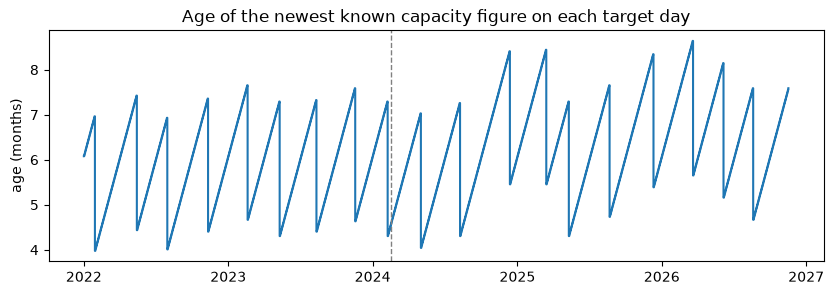

In [10]:
def utc(times) -> np.ndarray:
    """Time-zone-aware times as naive UTC datetime64, for searchsorted."""
    return pd.DatetimeIndex(times).tz_convert("UTC").tz_localize(None).to_numpy()


order = known.sort_values("known_at")
known_times = utc(order["known_at"])
# A release re-uploaded years later is "known" late but is not the newest figure: take the
# newest reference date among everything known so far.
newest_ref = order.index.to_series().cummax().to_numpy()


def newest_known_ref(decision: pd.DatetimeIndex) -> pd.DatetimeIndex:
    i = np.searchsorted(known_times, utc(decision), side="right") - 1
    assert (i >= 0).all(), "a decision time before any release was known"
    return pd.DatetimeIndex(newest_ref[i])


def age_frame(first: str, last) -> pd.DataFrame:
    days = pd.date_range(first, last, freq="D", tz=JST)
    ref = newest_known_ref(days - pd.Timedelta(hours=15))
    return pd.DataFrame(
        {"ref_date": ref, "age_days": (days.tz_localize(None) - ref).days}, index=days.date
    )


window = age_frame("2024-02-17", TODAY + pd.Timedelta(days=1))
since_2022 = age_frame("2022-01-01", TODAY + pd.Timedelta(days=1))
for name, frame in (("training window", window), ("since 2022", since_2022)):
    d = frame["age_days"]
    lo, hi = d.min(), d.max()
    print(
        f"{name}: age {lo}–{hi} days ({lo / 30.44:.1f}–{hi / 30.44:.1f} months),",
        f"median {d.median():.0f} days",
    )
print(
    "tomorrow's forecast uses the release for",
    window["ref_date"].iloc[-1].date(),
    "| age",
    window["age_days"].iloc[-1],
    "days",
)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(pd.to_datetime(since_2022.index), since_2022["age_days"] / 30.44, drawstyle="steps-post")
ax.axvline(pd.Timestamp("2024-02-17"), color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("age (months)")
ax.set_title("Age of the newest known capacity figure on each target day")
plt.show()

**What it shows.** **Observed:**

- In the training window, the newest figure a forecast can use is **123 to 263 days old (4.0 to 8.6 months), median 194 days (6.4 months)**; since 2022, 121 to 263 days
- Tomorrow's forecast (target 2026-11-17) uses the figure for the end of March 2026, which is 231 days old. The end-of-June figure, due around December, is not out yet
- The sawtooth in the plot: a release lands four to five and a half months after its quarter (the troughs), then ages for three months until the next one (the peaks)

**Learned → design:** two consequences.

1. **The leak.** Joining capacity on its reference date ("the figure for the quarter containing D") uses a number published four to six months after D. In a backtest it is invisible: the number looks right, and it is right, but nobody had it at the time. `known_at` is the fix; a future-poison test (step 6) catches a join that ignores it
2. **The bias.** The fleet grows while the figure ages. Section 7 measures what that costs, and whether extrapolating helps

## 4. The files' layout

**Step: one parser for every sheet.** Each workbook has six sheets (counts and capacity of new and transferred installations, certified counts and capacity). Every sheet has a title in row 1, a three-row header in rows 3–5 (category, size class, "of which" subset, with merged cells left empty) and one row per area. A single function can melt any sheet into rows of *(sheet, area, header path, value)*: the shape ODS would store. The header path joins the three header rows (`太陽光発電設備/10kW以上/うち50kW未満`, "solar / 10 kW and over / of which under 50 kW").

In [11]:
def header_paths(head: list[tuple]) -> list[str | None]:
    """Join the three header rows; merged cells are empty, so carry labels right in their group."""
    top, mid, low = (list(r) for r in head)
    paths = [None]
    for j in range(1, len(top)):
        if top[j] is None:
            top[j] = top[j - 1]
            if mid[j] is None:
                mid[j] = mid[j - 1]
        paths.append("/".join(str(x) for x in (top[j], mid[j], low[j]) if x is not None) or None)
    return paths


def melt(path: Path) -> pd.DataFrame:
    """Every sheet of one workbook as (sheet, title, area, header path, value)."""
    wb = openpyxl.load_workbook(io.BytesIO(path.read_bytes()), read_only=True, data_only=True)
    out = []
    for ws in wb.worksheets:
        rows = list(ws.iter_rows(values_only=True))
        paths = header_paths(rows[2:5])
        for r in rows[5:]:
            if not isinstance(r[0], str):
                continue
            for j, value in enumerate(r[1:], start=1):
                if j < len(paths) and paths[j] and isinstance(value, (int, float)):
                    out.append((ws.title, rows[0][0], r[0], paths[j], float(value)))
    return pd.DataFrame(out, columns=["sheet", "title", "area", "path", "value"])


def melted(table: str, ref: pd.Timestamp) -> pd.DataFrame:
    cached = CACHE / "melted" / f"{table}_{ref:%Y-%m}.parquet"
    if not cached.exists():
        cached.parent.mkdir(parents=True, exist_ok=True)
        melt(local(table, ref)).to_parquet(cached)
    return pd.read_parquet(cached)


parsable = releases[releases["served_as"].str.endswith(".xlsx")]
print(
    "not .xlsx, left out:", releases.loc[~releases.index.isin(parsable.index), "served_as"].tolist()
)
long = {(r.table, r.ref_date): melted(r.table, r.ref_date) for r in parsable.itertuples()}
newest = long[("A", releases["ref_date"].max())]
print(
    newest.groupby(["sheet", "title"]).agg(
        areas=("area", "nunique"), paths=("path", "nunique"), rows=("value", "size")
    )
)
newest[newest["sheet"] == "表A②－１"]["path"].drop_duplicates().head(12).tolist()

not .xlsx, left out: ['A_pref201803.xls', 'B_city201803.xls', 'A_pref201712.xls', 'B_city201712.xls', 'A_pref201709.xls', 'B_city201709.xls']


                                 areas  paths  rows
sheet title                                        
表A①－１ 【表A ①-１】　都道府県別導入件数（新規認定分）     48     28  1344
表A①－２ 【表A ①-２】　都道府県別導入件数（移行認定分）     48     27  1296
表A②－１ 【表A ②-１】　都道府県別導入容量（新規認定分）     48     34  1632
表A②－２ 【表A ②-２】　都道府県別導入容量（移行認定分）     48     33  1584
表A③   【表A ③】　都道府県別認定件数（新規認定分）       48     28  1344
表A④   【表A ④】　都道府県別認定容量（新規認定分）       48     34  1632


['太陽光発電設備/10kW未満',
 '太陽光発電設備/10kW未満/うち自家発電設備併設',
 '太陽光発電設備/10kW以上',
 '太陽光発電設備/10kW以上/うち50kW未満',
 '太陽光発電設備/10kW以上/うち50kW以上500kW未満',
 '太陽光発電設備/10kW以上/うち500kW以上1,000kW未満',
 '太陽光発電設備/10kW以上/うち1,000kW以上2,000kW未満',
 '太陽光発電設備/10kW以上/うち2,000kW以上',
 '風力発電設備/20kW未満',
 '風力発電設備/20kW以上',
 '風力発電設備/20kW以上/うち洋上風力',
 '水力発電設備/200kW未満']

**What it shows.** **Observed:** six sheets per workbook, each with 48 area rows (47 prefectures and `合計`, the total) and 27 to 34 header paths. The paths read naturally: `太陽光発電設備/10kW未満/うち自家発電設備併設` is "solar, under 10 kW, of which with own-use generation". An "of which" path is a subset of its parent, so summing every path double counts.

**Learned → design:** one melt function covers all six sheets of both tables, so the ODS shape is **semi-long**: one row per (sheet, area, header path), with its value. ODS keeps the source's labels. DWD picks the paths it needs and never adds an "of which" path to its parent.

**Step: is the layout the same in every file?** Compare each file's sheet titles and header paths with the newest file of its table, and count area rows.

In [12]:
def layout(df: pd.DataFrame) -> dict:
    return {
        "titles": tuple(
            df[["sheet", "title"]].drop_duplicates().itertuples(index=False, name=None)
        ),
        "paths": frozenset(zip(df["sheet"], df["path"], strict=True)),
    }


checks = []
for table in ("A", "B"):
    keys = sorted(k for k in long if k[0] == table)
    ref_layout = layout(long[keys[-1]])
    for key in keys:
        df, lay = long[key], layout(long[key])
        checks.append(
            {
                "table": table,
                "ref_date": key[1].date(),
                "same_titles": lay["titles"] == ref_layout["titles"],
                "paths_missing": len(ref_layout["paths"] - lay["paths"]),
                "paths_extra": len(lay["paths"] - ref_layout["paths"]),
                "areas": df["area"].nunique(),
                "rows": len(df),
            }
        )
checks = pd.DataFrame(checks)
print(
    checks.groupby("table").agg(
        files=("ref_date", "count"), rows=("rows", "sum"), same_titles=("same_titles", "sum")
    )
)
checks[(~checks["same_titles"]) | (checks["paths_missing"] > 0) | (checks["paths_extra"] > 0)]

       files      rows  same_titles
table                              
A         33    291456           33
B         33  10868696           33


,table,ref_date,same_titles,paths_missing,paths_extra,areas,rows


**What it shows.** **Observed:** all 33 `.xlsx` files of each table have the same sheet titles and the same header paths: one layout from the end of June 2017 to the end of March 2026. The three releases from end of September 2017 to end of March 2018 are `.xls` files (the older Excel format) and are left out. Melted, table A is 291,456 rows over 33 files (about 8,800 per release), table B 10,868,696 (about 330,000 per release).

**Learned → design:** one parser per table, checked against the known titles and paths: a file whose header paths differ is refused, the ODS rule. Eleven million rows for table B is still small for BigQuery, and it grows by a third of a million a quarter. The `.xls` releases are six years older than the training window and are not captured.

**Step: what unit?** No sheet states one. Check the newest table A's national totals against the page's own summary, which is in 万kW (10 MW).

In [13]:
SOLAR_PATHS = ["太陽光発電設備/10kW未満", "太陽光発電設備/10kW以上"]
INSTALLED = ("表A②－１", "表A②－２", "表B②－１", "表B②－２")
total = newest[
    (newest["area"] == "合計") & newest["sheet"].isin(INSTALLED) & newest["path"].isin(SOLAR_PATHS)
]
print(total.pivot_table(index="path", columns="sheet", values="value"))
i = lines.index("太陽光(住宅:10kW未満)")
print(
    "page, solar under 10 kW (certified, installed new, installed transferred):",
    lines[i + 1 : i + 4],
)

sheet                  表A②－１        表A②－２
path                                     
太陽光発電設備/10kW以上  6.010070e+07   267763.667
太陽光発電設備/10kW未満  1.290432e+07  4724470.467
page, solar under 10 kW (certified, installed new, installed transferred): ['1,307.4万kW', '1,290.4万kW', '472.4万kW']


**What it shows.** **Observed:** table A's national total of installed solar under 10 kW is 12,904,324 (new) and 4,724,470 (transferred); the page says 1,290.4万kW and 472.4万kW. The values are **kW**. They also carry floating-point noise (`490211.90000004787`), so the cells hold computed sums.

**Learned → design:** ODS stores the values as FLOAT, as found. DWD converts kW to MW for the area's total.

## 5. The TEPCO area

**Source:** TEPCO Power Grid's [last-resort supply terms](https://www.tepco.co.jp/pg/company/clause/pdf/220101henkou001-j.pdf) (最終保障供給約款, 2022) name its area: 「栃木県，群馬県，茨城県，埼玉県，千葉県，東京都，神奈川県，山梨県，静岡県（富士川以東）」 ("Tochigi, Gunma, Ibaraki, Saitama, Chiba, Tokyo, Kanagawa, Yamanashi, and Shizuoka east of the Fuji River").

**Step: cut Shizuoka by municipality.** Table B has one row per municipality. The 20 municipalities east of the river are our classification from the river's course (not a publisher's list). The river runs *through* two of them, Fujinomiya and Fuji; they are counted in full, and their total is the most this can be wrong by.

In [14]:
TEPCO_PREFECTURES = [
    "茨城県",
    "栃木県",
    "群馬県",
    "埼玉県",
    "千葉県",
    "東京都",
    "神奈川県",
    "山梨県",
]
SHIZUOKA_EAST = [
    "静岡県" + m
    for m in (
        "沼津市",
        "熱海市",
        "三島市",
        "富士宮市",
        "伊東市",
        "富士市",
        "御殿場市",
        "下田市",
        "裾野市",
        "伊豆市",
        "伊豆の国市",
        "賀茂郡東伊豆町",
        "賀茂郡河津町",
        "賀茂郡南伊豆町",
        "賀茂郡松崎町",
        "賀茂郡西伊豆町",
        "田方郡函南町",
        "駿東郡清水町",
        "駿東郡長泉町",
        "駿東郡小山町",
    )
]
SPLIT_BY_RIVER = ["静岡県富士宮市", "静岡県富士市"]


def solar_kw(df: pd.DataFrame) -> pd.Series:
    """Installed solar (new and transferred, under and over 10 kW) per area, in kW."""
    sel = df[df["sheet"].isin(INSTALLED) & df["path"].isin(SOLAR_PATHS)]
    return sel.groupby("area")["value"].sum()


rows = []
for ref in sorted(parsable["ref_date"].unique()):
    by_pref, by_city = solar_kw(long[("A", ref)]), solar_kw(long[("B", ref)])
    shizuoka_cities = by_city[by_city.index.str.startswith("静岡県")]
    rows.append(
        {
            "ref_date": ref,
            "prefectures_kw": by_pref[TEPCO_PREFECTURES].sum(),
            "shizuoka_east_kw": by_city.reindex(SHIZUOKA_EAST).sum(),
            "split_cities_kw": by_city.reindex(SPLIT_BY_RIVER).sum(),
            "shizuoka_a_minus_b_kw": by_pref["静岡県"] - shizuoka_cities.sum(),
            "shizuoka_unknown_city_kw": by_city.get("静岡県市町村不明", 0.0),
            "missing_east_cities": int(by_city.reindex(SHIZUOKA_EAST).isna().sum()),
        }
    )
cap = pd.DataFrame(rows).set_index("ref_date")
cap["tepco_kw"] = cap["prefectures_kw"] + cap["shizuoka_east_kw"]
cap["tepco_gw"] = (cap["tepco_kw"] / 1e6).round(2)
cap["growth_pct_q"] = (cap["tepco_kw"].pct_change() * 100).round(2)
cap["split_share_pct"] = (cap["split_cities_kw"] / cap["tepco_kw"] * 100).round(2)
cap = cap[cap.index >= "2018-06-30"].join(known)
print(
    "A vs B for Shizuoka, max |difference| (kW):", cap["shizuoka_a_minus_b_kw"].abs().max().round(1)
)
print("Shizuoka capacity with no municipality (kW), max:", cap["shizuoka_unknown_city_kw"].max())
print("east-of-river municipalities missing from a file:", cap["missing_east_cities"].max())
cap[["tepco_gw", "growth_pct_q", "split_share_pct", "known_at", "basis"]].tail(12)

A vs B for Shizuoka, max |difference| (kW): 6.0
Shizuoka capacity with no municipality (kW), max: 9038.000000000013
east-of-river municipalities missing from a file: 0


,tepco_gw,growth_pct_q,split_share_pct,known_at,basis
ref_date,,,,,
2023-06-30,18.56,1.48,1.06,2023-11-17 00:00:00+09:00,announced
2023-09-30,18.75,1.01,1.06,2024-02-07 00:00:00+09:00,announced
2023-12-31,18.97,1.14,1.06,2024-05-01 00:00:00+09:00,announced
2024-03-31,19.15,0.97,1.06,2024-08-08 00:00:00+09:00,announced
2024-06-30,19.31,0.86,1.05,2024-12-12 00:00:00+09:00,announced
2024-09-30,19.48,0.86,1.05,2025-03-14 00:00:00+09:00,announced
2024-12-31,19.69,1.06,1.05,2025-05-10 00:00:00+09:00,announced
2025-03-31,19.93,1.23,1.05,2025-08-21 00:00:00+09:00,announced
2025-06-30,20.03,0.51,1.05,2025-12-10 00:00:00+09:00,announced


**What it shows.** **Observed:**

- Table A's Shizuoka total and the sum of table B's Shizuoka municipalities agree within 6 kW in every release, so the cut works on consistent numbers
- Shizuoka capacity with no municipality (`静岡県市町村不明`) is at most 9 MW in any release, and all 20 eastern municipalities are in every file
- **The TEPCO area had 20.58 GW of FIT/FIP solar at the end of March 2026**, up from 18.75 GW at the end of September 2023. It grows 0.5% to 1.5% a quarter, about 1% typically
- Fujinomiya and Fuji, the two municipalities the river runs through, hold 1.04% to 1.06% of the area's capacity: the most the Shizuoka cut can be off by
- Every release from end of June 2023 on is known by its announcement

**Learned → design:** DWD computes the area's capacity as the eight prefectures from table A plus the 20 eastern municipalities from table B, solar only: under and over 10 kW, new and transferred. The cut is worth the second table: all of Shizuoka would add 2.0 GW, about 10% too much.

## 6. Against what the grid saw

**Step: compare with TEPCO's own actuals** in dev ODS: the quarterly peak of solar output, curtailment added back, over the capacity for that quarter's end. This uses hindsight (the release describing the quarter, whenever it came out); it is a check on the figure, not a feature. Two grains: the yearly files are hourly in 万kWh (×10 for MW averaged over the hour) up to January 2024; the monthly files are 30-minute MW from February 2024. A 30-minute peak runs a little above an hourly one.

/home/junda/workspaces/jepx-tokyo-forecast/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2131: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


        count    min    50%    max
grain                             
30 min    9.0  0.709  0.812  0.862
hourly   24.0  0.658  0.776  0.915


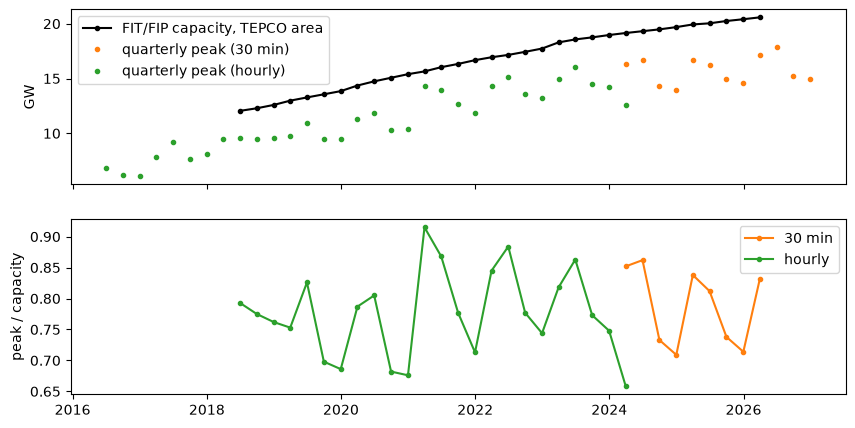

q               Q1     Q2     Q3     Q4
grain  year                            
30 min 2024  0.852  0.862  0.733  0.709
       2025  0.838  0.812  0.738  0.714
       2026  0.832   <NA>   <NA>   <NA>
hourly 2024  0.658   <NA>   <NA>   <NA>
       2018   <NA>  0.793  0.775  0.762
       2019  0.753  0.826  0.698  0.686
       2020  0.787  0.805  0.682  0.676
       2021  0.915  0.868  0.777  0.713
       2022  0.845  0.884  0.777  0.744
       2023  0.818  0.863  0.773  0.748

In [15]:
def bigquery_project() -> str:
    if project := os.environ.get("JTF_BIGQUERY_PROJECT"):
        return project
    env = dict(
        line.split("=", 1)
        for line in Path("../.env").read_text().splitlines()
        if "=" in line and not line.startswith("#")
    )
    return env["JTF_BIGQUERY_PROJECT"]


bq = bigquery.Client(project=bigquery_project())
peaks = bq.query("""
    SELECT DATE_TRUNC(day, QUARTER) AS quarter, grain, MAX(mw) AS peak_mw,
           COUNT(DISTINCT day) AS days
    FROM (
      SELECT PARSE_DATE('%Y/%m/%d', date) AS day, 'hourly' AS grain,
             10 * (solar + IFNULL(solar_curtailed, 0)) AS mw
      FROM ods.tepco_actuals_yearly
      UNION ALL
      SELECT PARSE_DATE('%Y/%m/%d', date), '30 min', solar + IFNULL(solar_curtailed, 0)
      FROM ods.tepco_actuals
    )
    GROUP BY quarter, grain
    ORDER BY quarter, grain
""").to_dataframe()
peaks["ref_date"] = pd.to_datetime(peaks["quarter"]) + pd.offsets.QuarterEnd()
peaks = peaks.join(cap["tepco_kw"], on="ref_date")
peaks["peak_over_capacity"] = (peaks["peak_mw"] * 1000 / peaks["tepco_kw"]).round(3)
print(peaks.groupby("grain")["peak_over_capacity"].describe()[["count", "min", "50%", "max"]])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot(
    cap.index,
    cap["tepco_kw"] / 1e6,
    marker=".",
    color="black",
    label="FIT/FIP capacity, TEPCO area",
)
for (grain, g), color in zip(peaks.groupby("grain"), ("tab:orange", "tab:green"), strict=True):
    ax1.plot(
        g["ref_date"],
        g["peak_mw"] / 1000,
        marker=".",
        linestyle="none",
        color=color,
        label=f"quarterly peak ({grain})",
    )
    ax2.plot(g["ref_date"], g["peak_over_capacity"], marker=".", color=color, label=grain)
ax1.set_ylabel("GW")
ax1.legend()
ax2.set_ylabel("peak / capacity")
ax2.legend()
plt.show()
peaks["year"] = pd.to_datetime(peaks["quarter"]).dt.year
peaks["q"] = "Q" + pd.to_datetime(peaks["quarter"]).dt.quarter.astype(str)
peaks.pivot_table(index=["grain", "year"], columns="q", values="peak_over_capacity").round(3)

**What it shows.** **Observed:**

- The quarterly peak is 68% to 92% of the FIT/FIP capacity at the end of the quarter, never above it (the hourly 0.66 is a quarter with only January's data)
- It is seasonal: 0.75 to 0.92 from January to June, 0.68 to 0.78 from July to December (hot panels in summer, low sun in autumn and winter)
- **A step in early 2021.** TEPCO's monthly solar peaks from January 2021 run 17% to 27% above the same months a year earlier (14.31 GW in March 2021 against 11.30 GW in March 2020), while FIT/FIP capacity grew about 10% a year. The April–June ratio goes from 0.83 and 0.81 (2019, 2020) to 0.87, 0.88 and 0.86 (2021–2023, hourly). The cause is not established here: neither TEPCO's download pages nor a search turned up a stated change in how its solar figure is estimated
- **Since 2021, no drift:** the April–June ratio is 0.87, 0.88, 0.86 (2021–2023, hourly) and 0.86, 0.81 (2024–2025, 30 minutes). If solar outside FIT/FIP were growing much faster than the scheme, the ratio would climb; at this resolution it does not
- The last three quarters cannot be checked at all, because their capacity isn't published yet

**Learned → design:**

- FIT/FIP capacity is a usable scale for the area's solar: since 2021, apart from the season, which the model sees through the day of year and clear-sky inputs, the ratio holds steady
- The 2021 step is three years before the training window and doesn't touch it. Anything that reaches further back into TEPCO's solar actuals (a long climatology, say) has to allow for it
- **The F5 range check needs a floor as well as a ceiling.** The highest ratio seen is 0.92, so output above capacity is a unit error, not a sunny day: kWh per slot read as MW (500 times too large) shows at once. But 万kW read as MW is ten times too *small* and passes "under capacity". A floor over several days (say, the week's peak above a third of capacity) catches it. F5's design gets both
- This is a coarse check: one peak per quarter depends on its clearest day. A sharper one, on clear-sky days with pvlib, belongs in the features notebook

## 7. The stale figure: carry it or extrapolate?

Section 3 showed the newest figure is months old when used, and the fleet grows meanwhile. Two candidate estimates of capacity on target day D, each using only releases known at 09:00 on D−1:

- **Carry:** the newest known figure as it is
- **Trend:** a straight line through the newest four known releases (one year), extended to D

**Step: score both against hindsight.** The "true" capacity on D is the straight line between the two releases whose reference dates bracket D (known only later). Score every target day from 2022 (section 3 says why not earlier) up to the newest reference date, and separately the training window. Also measure the **jump**: how much the estimate moves on the day a new release becomes known.

In [16]:
series = cap.sort_values("known_at")
ref_ord = cap.index.map(pd.Timestamp.toordinal).to_numpy()
truth_kw = cap["tepco_kw"].to_numpy()
days = pd.date_range("2022-01-01", cap.index.max(), freq="D", tz=JST)
newest_known = (
    np.searchsorted(utc(series["known_at"]), utc(days - pd.Timedelta(hours=15)), side="right") - 1
)
day_ord = days.tz_localize(None).map(pd.Timestamp.toordinal).to_numpy()

carry, trend = [], []
for d, k in zip(day_ord, newest_known, strict=True):
    known = series.iloc[: k + 1].sort_index()
    carry.append(known["tepco_kw"].iloc[-1])
    last4 = known.tail(4)
    slope, intercept = np.polyfit(last4.index.map(pd.Timestamp.toordinal), last4["tepco_kw"], 1)
    trend.append(slope * d + intercept)

scores = pd.DataFrame(
    {"truth": np.interp(day_ord, ref_ord, truth_kw), "carry": carry, "trend": trend},
    index=days.date,
)


def summary(frame: pd.DataFrame) -> pd.DataFrame:
    out = {}
    for method in ("carry", "trend"):
        err = (frame[method] / frame["truth"] - 1) * 100
        jump = frame[method].pct_change().abs() * 100
        out[method] = {
            "bias_pct": err.mean(),
            "mae_pct": err.abs().mean(),
            "max_abs_pct": err.abs().max(),
            "largest_jump_pct": jump.max(),
        }
    return pd.DataFrame(out).round(2)


print("2022-01-01 to", cap.index.max().date())
print(summary(scores))
print("\ntraining window, 2024-02-17 to", cap.index.max().date())
print(summary(scores.loc[pd.Timestamp("2024-02-17").date() :]))

2022-01-01 to 2026-03-31
                  carry  trend
bias_pct          -2.58   0.26
mae_pct            2.58   0.74
max_abs_pct        5.32   2.74
largest_jump_pct   3.16   2.14

training window, 2024-02-17 to 2026-03-31
                  carry  trend
bias_pct          -1.93   0.33
mae_pct            1.93   0.44
max_abs_pct        2.86   2.14
largest_jump_pct   1.23   1.77


**What it shows.** **Observed:**

| | Carry | Trend |
| --- | --- | --- |
| Bias, training window | −1.93% | +0.33% |
| Mean absolute error, training window | 1.93% | 0.44% |
| Largest error, training window | 2.86% | 2.14% |
| Largest one-day jump, training window | 1.23% | 1.77% |
| Mean absolute error, 2022 to March 2026 | 2.58% | 0.74% |
| Largest error, 2022 to March 2026 | 5.32% | 2.74% |

- Carrying the figure runs about 2% low, and always low: its bias equals its error
- The trend line is about four times closer, with almost no bias
- In the training window the trend's jump on a release day is a little larger (1.77% against 1.23%): a new release changes the slope as well as the level, as when the end of June 2025 grew only 0.5%

**Learned → design:**

- DWS estimates capacity on day D with the **trend through the newest four known releases**, evaluated at D. A model scaled by a carried figure would learn a 2% bias that changes with the figure's age
- The jump is there with either method. On a release day forecasts move by up to about 2% for a reason that has nothing to do with the weather. The PRD's output check "no unexplained jump vs the last run" should know the capacity release days
- The "truth" here is itself a straight line between quarterly figures, so differences of a few tenths of a percent are within what this can measure

## 8. Weights for the weather points

The PRD averages the weather at a handful of Kanto points "by approximate solar capacity". `jtf.ingest.sources.WEATHER_POINTS` has nine, one per prefecture of the area, with Numazu for eastern Shizuoka. **Step: each point's share of the area's capacity**, at the newest release and at the one the training window starts with, and the rooftop (under 10 kW) share of each.

In [17]:
POINT_OF = {
    "東京都": "tokyo",
    "神奈川県": "yokohama",
    "埼玉県": "saitama",
    "千葉県": "chiba",
    "茨城県": "mito",
    "栃木県": "utsunomiya",
    "群馬県": "maebashi",
    "山梨県": "kofu",
    "静岡県(富士川以東)": "numazu",
}
assert set(POINT_OF.values()) == {name for name, _, _ in WEATHER_POINTS}


def point_shares(ref: pd.Timestamp) -> pd.DataFrame:
    rows = {}
    for size in SOLAR_PATHS:
        pref = (
            long[("A", ref)]
            .query("sheet in @INSTALLED and path == @size")
            .groupby("area")["value"]
            .sum()
        )
        city = (
            long[("B", ref)]
            .query("sheet in @INSTALLED and path == @size")
            .groupby("area")["value"]
            .sum()
        )
        rows[size] = pd.concat(
            [
                pref[TEPCO_PREFECTURES],
                pd.Series({"静岡県(富士川以東)": city.reindex(SHIZUOKA_EAST).sum()}),
            ]
        )
    kw = pd.DataFrame(rows).sum(axis=1)
    return pd.DataFrame(
        {
            "point": [POINT_OF[x] for x in kw.index],
            "share_pct": (kw / kw.sum() * 100).round(1),
            "rooftop_pct": (pd.DataFrame(rows)[SOLAR_PATHS[0]] / kw * 100).round(1),
        },
        index=kw.index,
    )


start_ref = pd.Timestamp(window["ref_date"].iloc[0])
then = point_shares(start_ref)[["share_pct"]].rename(
    columns={"share_pct": f"share_pct_{start_ref:%Y-%m}"}
)
shares = point_shares(cap.index.max()).join(then)
shares.sort_values("share_pct", ascending=False)

,point,share_pct,rooftop_pct,share_pct_2023-09
茨城県,mito,23.5,12.7,23.8
千葉県,chiba,17.8,21.0,18.3
栃木県,utsunomiya,16.4,13.4,16.6
群馬県,maebashi,14.1,15.5,14.7
埼玉県,saitama,10.8,42.6,10.7
神奈川県,yokohama,5.3,66.7,5.0
東京都,tokyo,4.9,83.8,3.7
山梨県,kofu,3.9,25.3,4.1
静岡県(富士川以東),numazu,3.3,34.3,3.2


**What it shows.** **Observed:**

- Four northern prefectures hold 72% of the area's capacity: Ibaraki 23.5%, Chiba 17.8%, Tochigi 16.4%, Gunma 14.1%. Tokyo holds 4.9%, Kanagawa 5.3%
- Shares move slowly, by 1.2 points at most since the end of September 2023. Tokyo's rose most, from 3.7% to 4.9%
- Rooftop systems (under 10 kW) are 84% of Tokyo's capacity and 67% of Kanagawa's, but 13% of Ibaraki's: the north is ground-mounted plants

**Learned → design:** weighting the nine points equally would give Tokyo, Yokohama, Kofu and Numazu 44% of the weight for 17% of the capacity. DWS weights each point by its prefecture's share at the newest known release, as of `T` like the capacity itself. For Tokyo-area solar, the weather that matters most is northern Kanto's.

## What this exploration made known

| We assumed | We found | So |
| --- | --- | --- |
| The capacity source was still to verify, with METI's FIT/FIP disclosure as the candidate | It publishes installed capacity by prefecture and by municipality every quarter, every release since mid-2017 is linked from one page, and the data may be reused with credit (section 1) | It becomes a tenth capture source, `meti_fit_capacity` |
| A release is known from "the publication date of each update" | Files go up before their announcement, by up to 16 days, and the publisher later moved its own dates earlier (section 2) | `known_at` is the end of the latest announcement date any stored copy of the page showed, never before the file. The page is captured every day, and its 52 archived copies are loaded as history |
| A file's URL can be built from its date, as for TEPCO and JEPX | The URLs are unguessable ids, found only through the page (section 2) | Capture reads this one page for its links. It still never opens a data file |
| A figure describes about the time it is used | It is 4.0 to 8.6 months old when used, median 6.4 (section 3) | Capacity is joined on `known_at`, never on the date it describes; a future-poison test guards that join |
| Carrying the newest figure is close enough | It runs about 2% low, always; a trend through the newest four releases is off by 0.44% on average (section 7) | DWS extends the figure with that trend, and keeps the carried figure beside it |
| The files might change shape, as TEPCO's do | One layout in all 33 `.xlsx` files, six sheets, values in kW (section 4) | Two semi-long ODS tables holding every sheet, plus `meti_fit_notices`: 18 tables in all. The three `.xls` releases of 2017–2018 are left out |
| Shizuoka belongs to the TEPCO area | Only the part east of the Fuji River does; all of Shizuoka would be 10% too much (section 5) | The area is eight prefectures from table A plus 20 municipalities from table B. Fuji and Fujinomiya, which the river runs through, count in full: at most about 1% |
| FIT/FIP capacity might drift away from what the grid sees | Since 2021 the peak-to-capacity ratio holds steady apart from the season, and never goes above 0.92 (section 6) | It is the scale for normalising output and error |
| "Under capacity" catches unit errors (F5) | 万kW read as MW is ten times too small, and passes (section 6) | F5 gets a floor over several days as well as the ceiling |
| The nine weather points weigh the same | Northern Kanto holds 72% of the capacity, Tokyo 4.9% (section 8) | Each point is weighted by its prefecture's share of capacity, as of `T` |
| A forecast moves when the weather does | A capacity release moves the estimate by up to about 2% overnight (section 7) | The output check "no unexplained jump vs the last run" knows the capacity release days |

Capacity follows the same contract as every other source: raw files never change, ODS changes only the format, `known_at` is derived in DWD, and the time machine replays capacity like any other input. A hand-maintained table (a dbt seed, say) would be simpler, but it carries no `known_at`: the time machine couldn't replay it, and section 3's leak would come back.

### Still open

- **TEPCO's solar actuals step up by about a fifth from January 2021**, twice the growth in capacity, with no stated change of method (section 6). It is outside the training window; anything reaching further back in TEPCO's actuals needs it explained first
- **How much solar sits outside FIT/FIP**, and whether it grows faster than the scheme. The ratio says not yet, but one peak per quarter is a coarse check; a clear-sky comparison in the features notebook is sharper
- **Whether certified but not yet installed capacity** (sheets ③ and ④) predicts the next release better than the trend

## Where the sources and the data disagree

| Where | Says | We found | Handled by |
| --- | --- | --- | --- |
| The page's notices | A publication date per release | Five releases' dates were edited after the fact, four of them backwards, one by 16 days to a day when a copy of the page didn't list the release yet (section 2) | `known_at` from the latest date any copy showed; the page stored daily from now on |
| The page's notice vs its heading, end of March 2019 | 18 July 2019 | The heading says "updated 31 July" and the file is from 31 July: the release was published again | The later date; the 18 July version is lost |
| `Last-Modified` vs the notices | – | Files went up 1 to 16 days before their announcement, and some were replaced 1 to 24 months after it | `Last-Modified` is a floor, never the `known_at` by itself |
| The page's "past releases" link | `A表、B表 過去公表分はこちら` ("past A and B tables here") | Answers with a "page not found" | The summary page links every release itself |
| ※4 on the page | Small errors while data is checked | Releases can change after publication, and the old versions are gone (the March 2019 case) | From now on the daily capture keeps each version it sees |
| TEPCO's solar actuals | – | Peaks step up by about a fifth from January 2021, twice the growth in FIT/FIP capacity; no stated change of method found (section 6) | Open; outside the training window |
| The definition of "installed" | FIT/FIP installations | Solar outside the scheme is not counted; the peak-to-capacity ratio shows no drift from it yet (section 6) | Accepted; watch the ratio |
| TEPCO's terms | "Shizuoka east of the Fuji River" | The river runs through Fujinomiya and Fuji; the municipal cut is our classification | Both counted in full: at most about 1% of the area |
| Our earlier estimate | The figure is 4.5 to 9 months old | 4.0 to 8.6 months (123 to 263 days) over the training window | Section 3 |

## Sources

| Page | Supports |
| --- | --- |
| [FIT/FIP disclosure site, summary page](https://www.fit-portal.go.jp/PublicInfoSummary) | The releases, notices, definitions and national totals |
| [Its terms of use](https://www.fit-portal.go.jp/Terms) | Free use, commercial included, with credit; compatible with CC BY 4.0 |
| [TEPCO Power Grid, last-resort supply terms (2022)](https://www.tepco.co.jp/pg/company/clause/pdf/220101henkou001-j.pdf) | The service area: eight prefectures and Shizuoka east of the Fuji River |
| [Wayback Machine snapshots of the summary page](https://web.archive.org/cdx/search/cdx?url=fit-portal.go.jp/PublicInfoSummary) | The notices as shown on each day since 2018 |